# Circuit Disagreement Research
## Notebook 01: Environment Setup

**Research objective:** Investigate whether targeted causal interventions
can identify computational omissions and intervention-induced context
distortions responsible for conflicting circuit evaluations.

### Current stage
Phase 1 — Environment setup and baseline preparation.

### Tasks
1. Verify GPU availability.
2. Install required libraries.
3. Establish persistent project storage.
4. Download and inspect benchmark resources.
5. Verify model inference and activation access.

### Expected deliverable
A reproducible Colab environment ready for baseline experiments.

In [22]:
import sys
import platform
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Operating system:", platform.system())

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
        "GB"
    )
else:
    raise RuntimeError("GPU unavailable. Enable a GPU in Colab runtime settings.")

Python: 3.13.16
PyTorch: 2.14.1+cu130
Operating system: Linux
Device: cuda
GPU: Tesla T4
GPU memory: 15.64 GB


In [23]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/circuit-disagreement-research")

folders = [
    "configs",
    "data",
    "models",
    "notebooks",
    "results",
    "figures",
    "logs",
]

for folder in folders:
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/circuit-disagreement-research


In [24]:
%pip install -q \
    transformer-lens \
    transformers \
    huggingface_hub \
    datasets \
    einops \
    scipy \
    pandas \
    matplotlib \
    pytest

In [25]:
from importlib.metadata import version
import torch

packages = [
    "torch",
    "transformer-lens",
    "transformers",
    "huggingface_hub",
    "datasets",
    "numpy",
    "scipy",
    "pandas",
]

for package in packages:
    print(f"{package}: {version(package)}")

print("\nCUDA available:", torch.cuda.is_available())

torch: 2.14.1+cu130
transformer-lens: 4.4.0
transformers: 5.22.1
huggingface_hub: 1.33.0
datasets: 4.8.5
numpy: 2.4.6
scipy: 1.16.3
pandas: 2.2.3

CUDA available: True


In [26]:
import subprocess
from pathlib import Path

REPO_DIR = Path("/content/InterpBench")

if not REPO_DIR.exists():
    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/FlyingPumba/InterpBench.git",
            str(REPO_DIR),
        ],
        check=True,
    )

print("Benchmark source:", REPO_DIR)

for path in sorted(REPO_DIR.iterdir()):
    print(path.name)

Benchmark source: /content/InterpBench
.circleci
.dockerignore
.git
.gitignore
DEMO_InterpBench.ipynb
Dockerfile
EXPERIMENTS.md
LICENSE
README.md
circuits_benchmark
main.py
metadata
poetry.lock
pyproject.toml
pytest.ini
tests


In [27]:
from transformer_lens.model_bridge import TransformerBridge
import torch

model = TransformerBridge.boot_transformers(
    "openai-community/gpt2",
    device=DEVICE,
)

print("GPT-2 loaded successfully.")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 loaded successfully.


In [28]:
text = "The capital of Ghana is"

with torch.no_grad():
    logits, cache = model.run_with_cache(text)

print("Input:", text)
print("Logits shape:", tuple(logits.shape))
print("Cached activation tensors:", len(cache))

print("\nFirst 10 activation keys:")

for key in list(cache.keys())[:10]:
    print(key)

Input: The capital of Ghana is
Logits shape: (1, 6, 50257)
Cached activation tensors: 493

First 10 activation keys:
embed.hook_in
embed.hook_out
hook_embed
pos_embed.hook_in
pos_embed.hook_out
hook_pos_embed
blocks.0.hook_in
blocks.0.hook_resid_pre
blocks.0.ln1.hook_in
blocks.0.ln1.hook_scale


# Phase 2: Baseline Circuit Analysis

## Objective
Investigate how modifying internal transformer activations
changes model predictions.

## Experiments
1. Establish baseline model behaviour.
2. Capture internal activations.
3. Perform activation patching.
4. Measure causal intervention effects.
5. Compare results across transformer layers.

## Deliverable
A reproducible baseline causal-intervention experiment.

Note: This experiment establishes intervention mechanics.
It does not yet identify or validate a complete circuit.

In [29]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from transformer_lens.model_bridge import TransformerBridge

torch.manual_seed(42)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
assert DEVICE == "cuda", "Enable a GPU in Colab."

model = TransformerBridge.boot_transformers(
    "openai-community/gpt2",
    device=DEVICE
)

model.eval()

print("Model loaded.")
print("Device:", DEVICE)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Model loaded.
Device: cuda


In [30]:
clean_prompt = "The capital of France is"
corrupted_prompt = "The capital of Italy is"

clean_tokens = model.to_tokens(clean_prompt)
corrupted_tokens = model.to_tokens(corrupted_prompt)

assert clean_tokens.shape == corrupted_tokens.shape

In [31]:
with torch.no_grad():
    clean_logits = model(clean_tokens)
    corrupted_logits = model(corrupted_tokens)

tokenizer = model.tokenizer

paris_ids = tokenizer.encode(" Paris", add_special_tokens=False)
rome_ids = tokenizer.encode(" Rome", add_special_tokens=False)

assert len(paris_ids) == 1
assert len(rome_ids) == 1

paris_id = paris_ids[0]
rome_id = rome_ids[0]

def logit_difference(logits):
    return logits[0, -1, paris_id] - logits[0, -1, rome_id]

clean_score = logit_difference(clean_logits).item()
corrupted_score = logit_difference(corrupted_logits).item()

print("Clean:", round(clean_score, 4))
print("Corrupted:", round(corrupted_score, 4))

Clean: 1.405
Corrupted: -4.4174


In [32]:
import re

def is_residual_hook(name):
    return bool(
        re.fullmatch(r"blocks\.\d+\.hook_resid_post", name)
    )

with torch.no_grad():
    _, clean_cache = model.run_with_cache(
        clean_tokens,
        names_filter=is_residual_hook
    )

print("Cached layers:", len(clean_cache))

for name in list(clean_cache.keys())[:5]:
    print(name, clean_cache[name].shape)

assert len(clean_cache) > 0, "No residual activations captured."

Cached layers: 12
blocks.0.hook_resid_post torch.Size([1, 6, 768])
blocks.1.hook_resid_post torch.Size([1, 6, 768])
blocks.2.hook_resid_post torch.Size([1, 6, 768])
blocks.3.hook_resid_post torch.Size([1, 6, 768])
blocks.4.hook_resid_post torch.Size([1, 6, 768])


In [33]:
layer = 5

hook_name = f"blocks.{layer}.hook_resid_post"

assert hook_name in clean_cache

clean_activation = clean_cache[hook_name]

def patch_activation(activation, hook):
    return clean_activation.to(
        device=activation.device,
        dtype=activation.dtype
    )

with torch.no_grad():
    patched_logits = model.run_with_hooks(
        corrupted_tokens,
        fwd_hooks=[
            (hook_name, patch_activation)
        ]
    )

patched_score = logit_difference(patched_logits).item()

print("Clean:", round(clean_score, 4))
print("Corrupted:", round(corrupted_score, 4))
print("Patched:", round(patched_score, 4))

Clean: 1.405
Corrupted: -4.4174
Patched: 1.405


In [34]:
denominator = clean_score - corrupted_score

assert abs(denominator) > 1e-6, (
    "Clean and corrupted scores are too similar."
)

recovery = (
    (patched_score - corrupted_score)
    / denominator
)

print(f"Recovery: {recovery:.2%}")

Recovery: 100.00%


In [35]:
results = []

layer_hooks = sorted(
    clean_cache.keys(),
    key=lambda name: int(name.split(".")[1])
)

for hook_name in layer_hooks:

    layer = int(hook_name.split(".")[1])

    target = clean_cache[hook_name]

    def patch(activation, hook, target=target):
        return target.to(
            device=activation.device,
            dtype=activation.dtype
        )

    with torch.no_grad():
        logits = model.run_with_hooks(
            corrupted_tokens,
            fwd_hooks=[(hook_name, patch)]
        )

    score = logit_difference(logits).item()

    recovery = (
        (score - corrupted_score)
        / (clean_score - corrupted_score)
    )

    results.append({
        "layer": layer,
        "patched_score": score,
        "recovery": recovery
    })

df = pd.DataFrame(results)

display(df)

,layer,patched_score,recovery
0,0,1.404953,1.0
1,1,1.404953,1.0
2,2,1.404953,1.0
3,3,1.404953,1.0
4,4,1.404953,1.0
5,5,1.404953,1.0
6,6,1.404953,1.0
7,7,1.404953,1.0
8,8,1.404953,1.0
9,9,1.404953,1.0


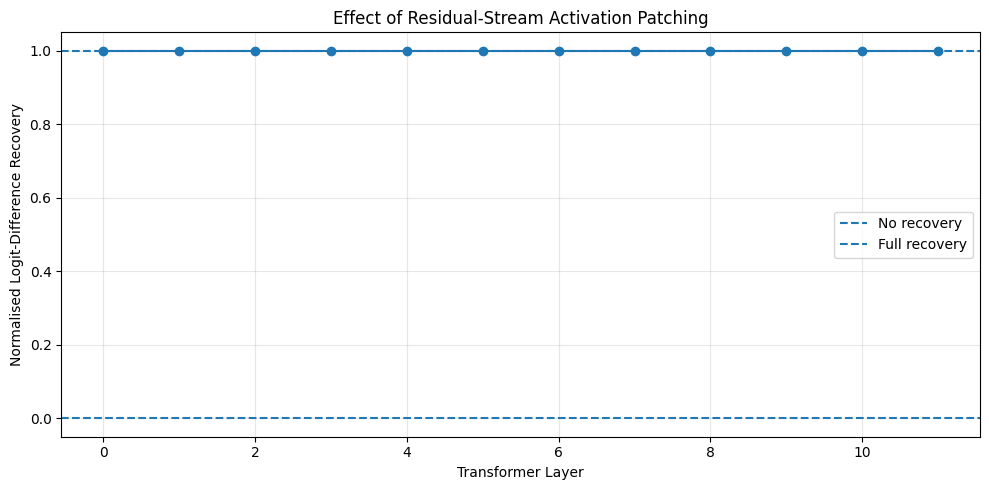

In [36]:
plt.figure(figsize=(10, 5))

plt.plot(
    df["layer"],
    df["recovery"],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--",
    label="No recovery"
)

plt.axhline(
    1,
    linestyle="--",
    label="Full recovery"
)

plt.xlabel("Transformer Layer")
plt.ylabel("Normalised Logit-Difference Recovery")
plt.title("Effect of Residual-Stream Activation Patching")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
from pathlib import Path
import json

RESULTS_DIR = Path(
    "/content/drive/MyDrive/"
    "circuit-disagreement-research/results"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

df.to_csv(
    RESULTS_DIR / "baseline_layer_patching.csv",
    index=False
)

metadata = {
    "model": "openai-community/gpt2",
    "clean_prompt": clean_prompt,
    "corrupted_prompt": corrupted_prompt,
    "target_tokens": [" Accra", " Paris"],
    "clean_score": clean_score,
    "corrupted_score": corrupted_score,
    "intervention": "full residual-state replacement",
    "seed": 42
}

with open(
    RESULTS_DIR / "baseline_metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=2)

print("Results saved successfully.")

Results saved successfully.
